# Entrenamiento del NPP-LSTM original

Objetivo: entrenar desde cero la arquitectura NPP-LSTM
utilizando la función de pérdida de NeuralPP.py.

Configuración original:
- Mcut: 3.5
- M0pred: 4.5
- Historial: 20 eventos
- Optimizador: Adam
- Learning rate: 0.001
- Batch size: 256
- Máximo: 400 épocas
- Early Stopping: paciencia de 30 épocas

La selección del mejor modelo se realizará exclusivamente
mediante validación. El conjunto de prueba no interviene.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

raiz = Path.cwd()
if not (raiz / "data").exists():
    raiz = raiz.parent

sys.path.insert(0, str(raiz / "src"))

from utils import datetime_to_hours, truncate_catalog_by_threshold
from npp_model import construir_npp
from npp_training import preparar_ventanas, perdida_npp

# Reproducibilidad
tf.keras.utils.set_random_seed(1)

# Leer el catálogo
catalogo = pd.read_csv(
    raiz / "data/raw/SISMOS_LIMA_FORMATO_MODELO_cat.csv"
)

catalogo = datetime_to_hours(catalogo).dropna()
catalogo = truncate_catalog_by_threshold(catalogo, 3.5)

tiempos = catalogo["time"].to_numpy()
magnitudes = catalogo["mw"].to_numpy()

# Separación temporal original
T_train = tiempos[tiempos < 450000]
M_train = magnitudes[tiempos < 450000]

# Normalización original
mu_t = np.log(np.diff(T_train)).mean()
sigma_t = np.log(np.diff(T_train)).std()
mu_m = np.log(M_train).mean()
sigma_m = np.log(M_train).std()

# Construir secuencias
X = preparar_ventanas(
    T_train, M_train, ventana=20, m0pred=4.5
)

# Último 20 % para validación
corte = int(len(X[0]) * 0.80)

X_train = tuple(a[:corte] for a in X)
X_val = tuple(a[corte:] for a in X)

print("Secuencias totales:", len(X[0]))
print("Entrenamiento:", len(X_train[0]))
print("Validación:", len(X_val[0]))

Secuencias totales: 1600
Entrenamiento: 1280
Validación: 320


In [2]:
modelo = construir_npp(
    ventana=20,
    mu_t=mu_t,
    sigma_t=sigma_t,
    mu_m=mu_m,
    sigma_m=sigma_m,
    m0pred=4.5
)

# Primer lote de 8 secuencias
lote = tuple(
    tf.convert_to_tensor(a[:8])
    for a in X_train
)

with tf.GradientTape() as tape:
    perdida, intensidad, densidad = perdida_npp(
        modelo, lote, entrenando=True
    )

gradientes = tape.gradient(
    perdida, modelo.trainable_variables
)

sin_gradiente = [
    variable.name
    for variable, gradiente in zip(
        modelo.trainable_variables, gradientes
    )
    if gradiente is None
]

print("Parámetros:", modelo.count_params())
print("Pérdida inicial:", float(perdida.numpy()))
print("Gradientes ausentes:", sin_gradiente)
print("Intensidad temporal:", intensidad.numpy()[:3])
print("Densidad de magnitud:", densidad.numpy()[:3])

assert not sin_gradiente, "Hay parámetros sin gradiente."
assert np.isfinite(float(perdida.numpy()))


Parámetros: 42370
Pérdida inicial: 303.5203552246094
Gradientes ausentes: []
Intensidad temporal: [[5.2963969e-06]
 [8.2842666e-09]
 [2.6001987e-06]]
Densidad de magnitud: [[2.0642922e-07]
 [3.4947951e-09]
 [8.7929052e-08]]


In [3]:
BATCH = 256
MAX_EPOCAS = 400
PACIENCIA = 30

optimizador = tf.keras.optimizers.Adam(
    learning_rate=0.001
)

ds_train = tf.data.Dataset.from_tensor_slices(
    X_train
).batch(BATCH)

ds_val = tf.data.Dataset.from_tensor_slices(
    X_val
).batch(BATCH)

@tf.function(reduce_retracing=True)
def paso_entrenamiento(lote):
    with tf.GradientTape() as tape:
        loss, _, _ = perdida_npp(
            modelo, lote, entrenando=True
        )

    gradientes = tape.gradient(
        loss, modelo.trainable_variables
    )

    optimizador.apply_gradients(
        zip(gradientes, modelo.trainable_variables)
    )

    return loss


@tf.function(reduce_retracing=True)
def paso_validacion(lote):
    loss, _, _ = perdida_npp(
        modelo, lote, entrenando=False
    )
    return loss


def evaluar_epoca(dataset, entrenando):
    suma = 0.0
    cantidad = 0

    for lote in dataset:
        if entrenando:
            loss = paso_entrenamiento(lote)
        else:
            loss = paso_validacion(lote)

        suma += float(loss.numpy())
        cantidad += int(lote[0].shape[0])

    return suma / cantidad


carpeta_modelos = raiz / "models"
carpeta_resultados = raiz / "results"

carpeta_modelos.mkdir(exist_ok=True)
carpeta_resultados.mkdir(exist_ok=True)

ruta_pesos = (
    carpeta_modelos / "NPP_original_W20.weights.h5"
)

ruta_historial = (
    carpeta_resultados / "historial_NPP_original_W20.csv"
)

historial = []
mejor_val = float("inf")
mejor_epoca = 0
sin_mejora = 0

for epoca in range(1, MAX_EPOCAS + 1):

    loss_train = evaluar_epoca(ds_train, True)
    loss_val = evaluar_epoca(ds_val, False)

    if not np.isfinite([loss_train, loss_val]).all():
        raise RuntimeError(
            f"Pérdida no finita en época {epoca}"
        )

    historial.append({
        "epoca": epoca,
        "loss": loss_train,
        "val_loss": loss_val
    })

    # Guardar registro de cada época
    pd.DataFrame(historial).to_csv(
        ruta_historial, index=False
    )

    if loss_val < mejor_val:
        mejor_val = loss_val
        mejor_epoca = epoca
        sin_mejora = 0

        modelo.save_weights(str(ruta_pesos))
    else:
        sin_mejora += 1

    if epoca == 1 or epoca % 10 == 0:
        print(
            f"Época {epoca}: "
            f"loss={loss_train:.4f}, "
            f"val_loss={loss_val:.4f}"
        )

    if sin_mejora >= PACIENCIA:
        print("Early Stopping activado.")
        break

# Recuperar los mejores pesos
modelo.load_weights(str(ruta_pesos))

print("\nEntrenamiento finalizado")
print("Mejor época:", mejor_epoca)
print("Mejor val_loss:", mejor_val)
print("Pesos guardados en:", ruta_pesos)

Época 1: loss=29.1137, val_loss=27.3659
Época 10: loss=15.9130, val_loss=15.2593
Época 20: loss=12.4058, val_loss=12.3577
Época 30: loss=12.1486, val_loss=12.2172
Época 40: loss=12.0576, val_loss=12.1831
Época 50: loss=12.0042, val_loss=12.1966
Época 60: loss=11.9787, val_loss=12.2022
Época 70: loss=11.9477, val_loss=12.2140
Early Stopping activado.

Entrenamiento finalizado
Mejor época: 41
Mejor val_loss: 12.182746505737304
Pesos guardados en: c:\Users\PC\Documents\NPP-Lima\models\NPP_original_W20.weights.h5


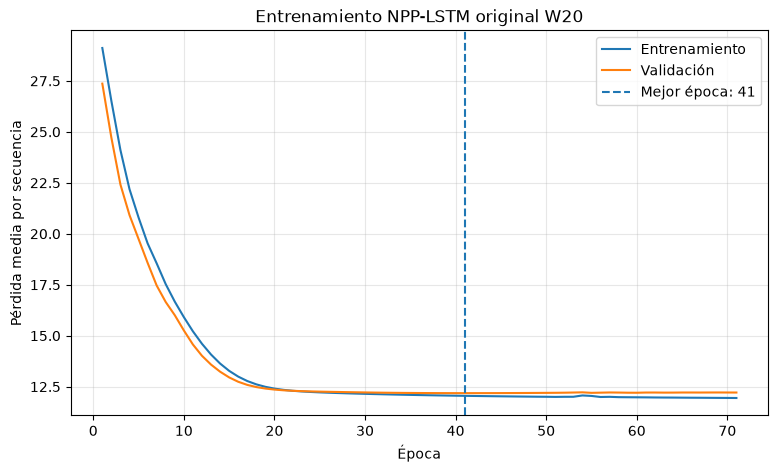

In [4]:
hist = pd.read_csv(ruta_historial)

plt.figure(figsize=(9, 5))

plt.plot(
    hist["epoca"], hist["loss"],
    label="Entrenamiento"
)

plt.plot(
    hist["epoca"], hist["val_loss"],
    label="Validación"
)

plt.axvline(
    mejor_epoca,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca}"
)

plt.xlabel("Época")
plt.ylabel("Pérdida media por secuencia")
plt.title("Entrenamiento NPP-LSTM original W20")
plt.legend()
plt.grid(alpha=0.3)
plt.show()